## Persiapan data

Data yang dipakai adalah McDonald's Nutrition Facts dari Kaggle, berisi 260 item menu beserta kandungan gizinya. Item dibagi menjadi 3 slot sesuai kategori di dataset:

- menu utama: Breakfast, Beef & Pork, Chicken & Fish, Salads
- lauk: Snacks & Sides, ditambah satu opsi tanpa lauk
- minuman: Beverages, Coffee & Tea, Smoothies & Shakes

Kategori Desserts tidak dipakai karena satu kali makan hanya terdiri dari menu utama, lauk, dan minuman. Opsi tanpa lauk dibuat sebagai baris dengan nilai gizi 0 dan diletakkan di nomor 0.

Semua item tetap dimasukkan, termasuk yang porsinya besar. Item yang tidak cocok untuk diet nantinya tersaring sendiri oleh batasan gizi, bukan dibuang dari awal.

Setelah dibagi, index tiap slot diurutkan ulang dari 0. Nomor index inilah yang nanti dipakai sebagai isi gen pada solusi.

In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.stats import ranksums

df = pd.read_csv("menu.csv")

kategori_utama = ["Breakfast", "Beef & Pork", "Chicken & Fish", "Salads"]
kategori_minum = ["Beverages", "Coffee & Tea", "Smoothies & Shakes"]

utama = df[df["Category"].isin(kategori_utama)]
minum = df[df["Category"].isin(kategori_minum)]

# opsi tanpa lauk, semua nilai gizinya 0
tanpa_lauk = pd.DataFrame([{kolom: 0 for kolom in df.columns}])
tanpa_lauk["Item"] = "(tanpa lauk)"
lauk = pd.concat([tanpa_lauk, df[df["Category"] == "Snacks & Sides"]])

# index dipakai sebagai nomor menu di kromosom
utama = utama.reset_index(drop=True)
lauk = lauk.reset_index(drop=True)
minum = minum.reset_index(drop=True)

print("Menu utama :", len(utama))
print("Lauk       :", len(lauk))
print("Minuman    :", len(minum))
print("Total kombinasi:", len(utama) * len(lauk) * len(minum))

Menu utama : 90
Lauk       : 14
Minuman    : 150
Total kombinasi: 189000


## Fungsi evaluasi

Setiap solusi terdiri dari 3 angka, yaitu nomor menu utama, nomor lauk, dan nomor minuman. Dari ketiga nomor itu dihitung total gizinya, lalu dinilai dengan dua objektif:

- f1 = selisih total kalori dengan target kalori
- f2 = kekurangan protein + kekurangan serat dari target

Keduanya diminimalkan. Natrium, gula, dan lemak jenuh dijadikan batasan. Kalau ada yang melebihi batas, nilai f1 dan f2 ditambah penalti sesuai seberapa jauh kelebihannya, jadi solusi yang melanggar akan kalah dari solusi yang memenuhi batasan.

Di sel ini juga ada fungsi untuk mencari solusi non-dominasi dan mengambil Pareto front dari sekumpulan solusi. Kalau ada beberapa menu dengan nilai f1 dan f2 yang sama, semuanya tetap disimpan.

In [2]:
# target gizi untuk sekali makan
TARGET_KALORI = 600
TARGET_PROTEIN = 25
TARGET_SERAT = 8

# batas maksimum, kurang lebih 1/3 batas harian
MAKS_NATRIUM = 800
MAKS_GULA = 17
MAKS_LEMAK_JENUH = 7

kolom_gizi = ["Calories", "Protein", "Dietary Fiber", "Sodium", "Sugars", "Saturated Fat"]
gizi_utama = utama[kolom_gizi].values
gizi_lauk = lauk[kolom_gizi].values
gizi_minum = minum[kolom_gizi].values

# nomor terbesar yang boleh dipakai tiap gen
BATAS_ATAS = np.array([len(utama) - 1, len(lauk) - 1, len(minum) - 1])


def nama_menu(x):
    return f"{utama['Item'][x[0]]} + {lauk['Item'][x[1]]} + {minum['Item'][x[2]]}"


def evaluasi(X):
    # X bisa berisi banyak solusi sekaligus, tiap baris [utama, lauk, minum]
    total = gizi_utama[X[:, 0]] + gizi_lauk[X[:, 1]] + gizi_minum[X[:, 2]]
    kalori, protein, serat, natrium, gula, lemak = total.T

    f1 = np.abs(kalori - TARGET_KALORI)

    kurang_protein = np.maximum(TARGET_PROTEIN - protein, 0)
    kurang_serat = np.maximum(TARGET_SERAT - serat, 0)
    f2 = kurang_protein + kurang_serat

    # kelebihan dibagi batasnya supaya ketiganya setara
    lebih_natrium = np.maximum(natrium - MAKS_NATRIUM, 0) / MAKS_NATRIUM
    lebih_gula = np.maximum(gula - MAKS_GULA, 0) / MAKS_GULA
    lebih_lemak = np.maximum(lemak - MAKS_LEMAK_JENUH, 0) / MAKS_LEMAK_JENUH
    pelanggaran = lebih_natrium + lebih_gula + lebih_lemak

    # pengali dibuat besar supaya solusi yang melanggar selalu kalah
    F = np.column_stack([f1 + 1000 * pelanggaran, f2 + 100 * pelanggaran])
    lolos = pelanggaran == 0
    return F, lolos


def non_dominasi(F):
    hasil = []
    for i in range(len(F)):
        # solusi i kalah kalau ada solusi lain yang tidak lebih buruk di semua objektif
        # dan lebih baik di salah satunya
        kalah = np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)
        if not kalah.any():
            hasil.append(i)
    return hasil


def ambil_pareto(X):
    X = np.unique(X, axis=0)
    F, lolos = evaluasi(X)
    X, F = X[lolos], F[lolos]
    if len(X) == 0:
        return X, F
    idx = non_dominasi(F)
    return X[idx], F[idx]

## Brute force

Karena jumlah kombinasinya masih bisa dihitung semua (90 × 14 × 150 = 189.000), setiap kombinasi dicek satu per satu. Kombinasi yang melanggar batasan dibuang, lalu dari sisanya diambil solusi yang non-dominasi.

Hasilnya adalah Pareto front sejati, yaitu jawaban yang benar-benar optimal untuk kasus ini. Front ini dipakai sebagai acuan untuk menilai hasil MOGA dan MOPSO, terutama pada perhitungan IGD.

In [3]:
from itertools import product

# semua kemungkinan [utama, lauk, minum]
semua = np.array(list(product(range(len(utama)), range(len(lauk)), range(len(minum)))))
F_semua, lolos = evaluasi(semua)

print("Total kombinasi :", len(semua))
print("Lolos batasan   :", lolos.sum(), f"({lolos.mean() * 100:.2f}%)")

X_lolos = semua[lolos]
F_lolos = F_semua[lolos]

idx = non_dominasi(F_lolos)
X_SEJATI = X_lolos[idx]
F_SEJATI = F_lolos[idx]

# urutkan dari f1 terkecil supaya enak dibaca
urutan = np.argsort(F_SEJATI[:, 0])
X_SEJATI, F_SEJATI = X_SEJATI[urutan], F_SEJATI[urutan]

print("\nPareto front sejati:", len(np.unique(F_SEJATI, axis=0)), "titik,", len(X_SEJATI), "menu")
for x, f in zip(X_SEJATI, F_SEJATI):
    print(f"f1 = {f[0]:3.0f} | f2 = {f[1]:2.0f} | {nama_menu(x)}")

Total kombinasi : 189000
Lolos batasan   : 1262 (0.67%)

Pareto front sejati: 4 titik, 5 menu
f1 =   0 | f2 =  6 | Filet-O-Fish + Kids French Fries + 1% Low Fat Milk Jug
f1 =  10 | f2 =  4 | Chicken McNuggets (6 piece) + Small French Fries + Nonfat Latte (Small)
f1 =  20 | f2 =  2 | Premium Bacon Ranch Salad (without Chicken) + Medium French Fries + Nonfat Latte (Small)
f1 =  20 | f2 =  2 | Premium Bacon Ranch Salad (without Chicken) + Medium French Fries + Nonfat Latte with Sugar Free French Vanilla Syrup (Small)
f1 = 150 | f2 =  0 | Premium Bacon Ranch Salad (without Chicken) + Large French Fries + Nonfat Latte (Small)


## Metrik evaluasi

Hasil MOGA dan MOPSO berupa sekumpulan solusi, jadi perlu metrik untuk membandingkannya. Ada tiga metrik yang dipakai:

- Hypervolume (HV): luas daerah yang didominasi Pareto front sampai titik acuan. Makin besar makin baik.
- Spacing: simpangan baku jarak tiap solusi ke tetangga terdekatnya. Makin kecil berarti sebarannya makin rata.
- IGD: rata-rata jarak dari tiap titik front sejati ke titik hasil algoritma yang paling dekat. Makin kecil berarti hasilnya makin dekat dan lengkap.

Titik acuan yang dipakai adalah (300, 15), sedikit lebih buruk dari nilai terburuk di front sejati. Titik ini juga dipakai untuk menormalisasi f1 dan f2 supaya skalanya sama. Semua metrik dihitung dari titik yang unik, jadi menu berbeda dengan nilai f1 dan f2 yang sama hanya dihitung sekali.

In [4]:
# titik terburuk, dipakai untuk HV dan normalisasi
TITIK_ACUAN = np.array([300.0, 15.0])


def hypervolume(F):
    F = np.unique(F, axis=0)
    F = F[(F[:, 0] < TITIK_ACUAN[0]) & (F[:, 1] < TITIK_ACUAN[1])]
    if len(F) == 0:
        return 0.0

    F = F[np.argsort(F[:, 0])]
    luas = 0.0
    f2_terkecil = TITIK_ACUAN[1]

    # luas dihitung per pita vertikal dari kiri ke kanan
    for i in range(len(F)):
        f1_kanan = F[i + 1, 0] if i + 1 < len(F) else TITIK_ACUAN[0]
        f2_terkecil = min(f2_terkecil, F[i, 1])
        luas += (f1_kanan - F[i, 0]) * (TITIK_ACUAN[1] - f2_terkecil)

    return luas / (TITIK_ACUAN[0] * TITIK_ACUAN[1])


def spacing(F):
    F = np.unique(F, axis=0) / TITIK_ACUAN
    if len(F) < 2:
        return np.nan

    jarak_terdekat = []
    for i in range(len(F)):
        jarak = np.abs(F - F[i]).sum(axis=1)
        jarak[i] = np.inf    # jarak ke diri sendiri tidak dihitung
        jarak_terdekat.append(jarak.min())

    return np.std(jarak_terdekat, ddof=1)


def igd(F):
    if len(F) == 0:
        return np.nan

    hasil = np.unique(F, axis=0) / TITIK_ACUAN
    sejati = np.unique(F_SEJATI, axis=0) / TITIK_ACUAN

    jarak = [np.linalg.norm(hasil - titik, axis=1).min() for titik in sejati]
    return np.mean(jarak)


print("HV front sejati     :", round(hypervolume(F_SEJATI), 4))
print("Spacing front sejati:", round(spacing(F_SEJATI), 4))

HV front sejati     : 0.92
Spacing front sejati: 0.2


## MOGA

MOGA yang dipakai mengikuti Fonseca & Fleming (1993). Langkah tiap generasinya:

1. Setiap solusi diberi rank = 1 + jumlah solusi lain yang mendominasinya. Solusi non-dominasi mendapat rank 1.
2. Populasi diurutkan berdasarkan rank, lalu fitness diberikan secara linear dari N (terbaik) sampai 1 (terburuk). Solusi dengan rank yang sama diberi fitness rata-ratanya.
3. Fitness sharing dilakukan di ruang objektif, hanya di antara solusi dengan rank yang sama. Jarak dihitung dengan norma tak hingga pada objektif yang sudah dinormalisasi. Fitness dibagi niche count, lalu diskalakan lagi supaya total fitness tiap rank tidak berubah.
4. Induk dipilih dengan stochastic universal sampling, lalu dikawinkan dengan crossover uniform dan dimutasi.

Nilai sigma share untuk 2 objektif yang dinormalisasi didapat dari persamaan di paper, hasilnya sigma = 2 / (N - 1). Semua anak hasil tiap generasi disimpan ke arsip, dan Pareto front akhir diambil dari arsip tersebut.

In [5]:
def moga(rng, N=50, generasi=400, p_mutasi=0.2):
    # sigma share untuk 2 objektif yang sudah dinormalisasi
    sigma = 2 / (N - 1)

    X = np.column_stack([rng.integers(0, b + 1, N) for b in BATAS_ATAS])
    arsip = X.copy()

    for g in range(generasi):
        F, _ = evaluasi(X)

        # rank = 1 + jumlah solusi yang mendominasi
        rank = np.array([1 + np.sum(np.all(F <= f, axis=1) & np.any(F < f, axis=1)) for f in F])

        # fitness diinterpolasi linear dari N (rank terbaik) sampai 1 (rank terburuk)
        urutan = np.argsort(rank, kind="stable")
        fitness = np.zeros(N)
        fitness[urutan] = np.linspace(N, 1, N)

        for r in np.unique(rank):
            anggota = np.where(rank == r)[0]

            # solusi dengan rank yang sama diberi fitness yang sama
            fitness[anggota] = fitness[anggota].mean()

            # sharing hanya di antara solusi dengan rank yang sama
            Fr = F[anggota]
            Fr = (Fr - Fr.min(axis=0)) / (np.ptp(Fr, axis=0) + 1e-9)
            jarak = np.abs(Fr[:, None] - Fr[None]).max(axis=2)
            niche = np.where(jarak < sigma, 1 - jarak / sigma, 0).sum(axis=1)

            total = fitness[anggota].sum()
            fitness[anggota] = fitness[anggota] / niche
            fitness[anggota] *= total / fitness[anggota].sum()

        # stochastic universal sampling
        kumulatif = np.cumsum(fitness)
        langkah = kumulatif[-1] / N
        titik = rng.uniform(0, langkah) + langkah * np.arange(N)
        terpilih = np.minimum(np.searchsorted(kumulatif, titik), N - 1)
        rng.shuffle(terpilih)

        anak = []
        for i in range(0, N, 2):
            p1, p2 = X[terpilih[i]], X[terpilih[i + 1]]

            # crossover uniform, tiap gen diambil dari salah satu induk
            ambil_p1 = rng.random(3) < 0.5
            for child in (np.where(ambil_p1, p1, p2), np.where(ambil_p1, p2, p1)):
                for j in range(3):
                    if rng.random() < p_mutasi:
                        child[j] = rng.integers(0, BATAS_ATAS[j] + 1)
                anak.append(child)

        X = np.array(anak)
        arsip = np.vstack([arsip, X])

        # arsip dirapikan tiap 20 generasi supaya tidak terlalu besar
        if g % 20 == 0:
            X_arsip, _ = ambil_pareto(arsip)
            if len(X_arsip) > 0:
                arsip = X_arsip

    return ambil_pareto(arsip)

## MOPSO

MOPSO yang dipakai mengikuti Coello, Pulido & Lechuga (2004). Setiap partikel adalah satu solusi. Posisinya disimpan sebagai bilangan real lalu dibulatkan ke nomor menu terdekat saat dievaluasi.

Langkah tiap iterasinya:

1. Ruang objektif dibagi menjadi grid (hypercube). Leader dipilih dengan roulette wheel, di mana hypercube yang isinya lebih sedikit punya peluang lebih besar, lalu satu solusi diambil acak dari hypercube itu.
2. Kecepatan dan posisi diperbarui dengan V = w·V + r1·(pbest − X) + r2·(leader − X). Kalau partikel keluar batas, posisinya ditahan di batas dan arah kecepatannya dibalik.
3. Mutasi diberikan dengan peluang yang mengecil seiring iterasi, sehingga di awal pencarian lebih banyak eksplorasi.
4. Arsip diisi solusi non-dominasi. Kalau arsip melebihi kapasitas, solusi dibuang dari hypercube yang paling ramai.
5. pbest diganti kalau posisi baru mendominasi pbest. Kalau keduanya tidak saling mendominasi, dipilih salah satu secara acak.

In [6]:
def kotak_grid(F, n_divisi):
    # nomor hypercube tiap solusi di ruang objektif
    bawah, atas = F.min(axis=0), F.max(axis=0)
    lebar = (atas - bawah) / n_divisi + 1e-9
    posisi = np.minimum(((F - bawah) / lebar).astype(int), n_divisi - 1)
    return posisi[:, 0] * n_divisi + posisi[:, 1]


def mopso(rng, N=50, iterasi=400, w=0.4, n_divisi=30, maks_arsip=100, laju_mutasi=0.5):
    bulat = lambda P: np.clip(np.rint(P), 0, BATAS_ATAS).astype(int)

    X = np.column_stack([rng.uniform(0, b, N) for b in BATAS_ATAS])
    V = np.zeros_like(X)
    F, _ = evaluasi(bulat(X))

    pbest, F_pbest = X.copy(), F.copy()

    idx = non_dominasi(F)
    arsip, F_arsip = bulat(X)[idx], F[idx]

    for t in range(iterasi):
        # pilih leader: hypercube yang lebih sepi punya peluang lebih besar
        kotak = kotak_grid(F_arsip, n_divisi)
        isi_kotak, jumlah = np.unique(kotak, return_counts=True)
        peluang = (10 / jumlah) / (10 / jumlah).sum()
        leader = np.empty_like(X)
        for i in range(N):
            k = rng.choice(isi_kotak, p=peluang)
            leader[i] = arsip[rng.choice(np.where(kotak == k)[0])]

        r1, r2 = rng.random((N, 3)), rng.random((N, 3))
        V = w * V + r1 * (pbest - X) + r2 * (leader - X)
        X = X + V

        # kalau keluar batas, posisi ditahan di batas dan arah kecepatan dibalik
        keluar = (X < 0) | (X > BATAS_ATAS)
        X = np.clip(X, 0, BATAS_ATAS)
        V[keluar] *= -1

        # mutasi, peluangnya mengecil sampai 0 di akhir iterasi
        pm = (1 - t / iterasi) ** (5 / laju_mutasi)
        for i in range(N):
            if rng.random() < pm:
                j = rng.integers(3)
                rentang = BATAS_ATAS[j] * pm
                X[i, j] = np.clip(X[i, j] + rng.uniform(-rentang, rentang), 0, BATAS_ATAS[j])

        F, _ = evaluasi(bulat(X))

        # update arsip, hanya simpan yang non-dominasi
        arsip = np.vstack([arsip, bulat(X)])
        F_arsip = np.vstack([F_arsip, F])
        arsip, unik = np.unique(arsip, axis=0, return_index=True)
        F_arsip = F_arsip[unik]
        idx = non_dominasi(F_arsip)
        arsip, F_arsip = arsip[idx], F_arsip[idx]

        # kalau arsip penuh, buang dari hypercube yang paling ramai
        while len(arsip) > maks_arsip:
            kotak = kotak_grid(F_arsip, n_divisi)
            isi_kotak, jumlah = np.unique(kotak, return_counts=True)
            terpadat = isi_kotak[np.argmax(jumlah)]
            buang = rng.choice(np.where(kotak == terpadat)[0])
            arsip, F_arsip = np.delete(arsip, buang, axis=0), np.delete(F_arsip, buang, axis=0)

        # update pbest
        for i in range(N):
            baru_menang = np.all(F[i] <= F_pbest[i]) and np.any(F[i] < F_pbest[i])
            lama_menang = np.all(F_pbest[i] <= F[i]) and np.any(F_pbest[i] < F[i])
            if baru_menang or (not lama_menang and rng.random() < 0.5):
                pbest[i], F_pbest[i] = X[i], F[i]

    return ambil_pareto(arsip)

## Eksperimen

MOGA dan MOPSO dijalankan masing-masing 30 kali karena keduanya algoritma acak dan hasilnya berbeda di setiap run. Seed yang dipakai 0 sampai 29 dan sama untuk kedua algoritma, jadi hasilnya bisa diulang dan perbandingannya adil.

Di setiap run dicatat nilai HV, Spacing, IGD, jumlah titik pada Pareto front, dan waktu komputasi. Hasilnya diringkas dalam bentuk rata-rata ± standar deviasi. Perbedaan HV dan IGD antara kedua algoritma diuji dengan Wilcoxon rank-sum pada taraf signifikansi 0,05.

In [7]:
JUMLAH_RUN = 30
hasil = {}

for nama, algoritma in [("MOGA", moga), ("MOPSO", mopso)]:
    catatan = {"HV": [], "Spacing": [], "IGD": [], "Jumlah titik": [], "Waktu (detik)": []}
    front = []

    for seed in range(JUMLAH_RUN):
        # seed sama untuk kedua algoritma supaya adil dan bisa diulang
        rng = np.random.default_rng(seed)

        mulai = time.time()
        X, F = algoritma(rng)
        catatan["Waktu (detik)"].append(time.time() - mulai)

        catatan["HV"].append(hypervolume(F))
        catatan["Spacing"].append(spacing(F))
        catatan["IGD"].append(igd(F))
        catatan["Jumlah titik"].append(len(np.unique(F, axis=0)))
        front.append((X, F))

    hasil[nama] = {"metrik": catatan, "front": front}
    print(nama, "selesai")

tabel = {}
for nama in hasil:
    metrik = hasil[nama]["metrik"]
    # nanmean dipakai karena spacing bisa nan kalau titiknya kurang dari 2
    tabel[nama] = {m: f"{np.nanmean(v):.4f} ± {np.nanstd(v):.4f}" for m, v in metrik.items()}
print(pd.DataFrame(tabel))
print()

for m in ["HV", "IGD"]:
    p = ranksums(hasil["MOGA"]["metrik"][m], hasil["MOPSO"]["metrik"][m]).pvalue
    print(f"Wilcoxon {m}: p = {p:.4f} ->", "signifikan" if p < 0.05 else "tidak signifikan")

MOGA selesai
MOPSO selesai
                          MOGA            MOPSO
HV             0.8976 ± 0.0320  0.8082 ± 0.0814
Spacing        0.2068 ± 0.0658  0.0552 ± 0.0933
IGD            0.0316 ± 0.0280  0.1088 ± 0.0466
Jumlah titik   3.5000 ± 0.5627  2.3000 ± 0.4583
Waktu (detik)  1.4241 ± 0.4315  1.6127 ± 0.4248

Wilcoxon HV: p = 0.0000 -> signifikan
Wilcoxon IGD: p = 0.0000 -> signifikan


## Visualisasi dan rekomendasi menu

Grafik menampilkan Pareto front sejati hasil brute force bersama Pareto front MOGA dan MOPSO dari run dengan HV tertinggi.

Dari Pareto front sejati diambil tiga rekomendasi:

- paling dekat target kalori, yaitu titik dengan f1 terkecil
- paling lengkap protein dan serat, yaitu titik dengan f2 terkecil
- kompromi, yaitu titik yang paling dekat ke titik ideal (0, 0) setelah f1 dan f2 dinormalisasi dengan titik acuan

Kalau ada beberapa menu dengan nilai f1 dan f2 yang sama, semuanya ditampilkan.

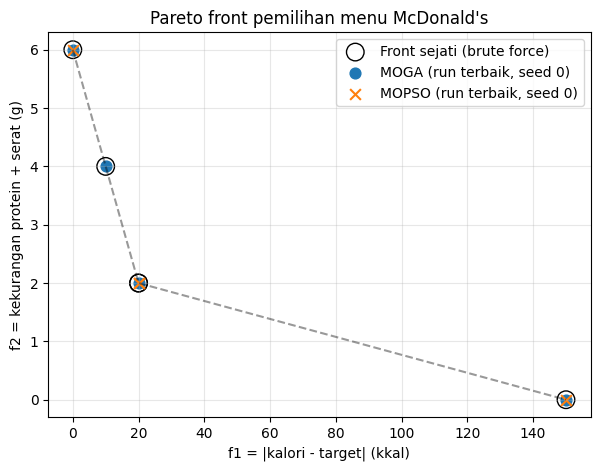

Paling dekat target kalori (f1 = 0, f2 = 6):
  - Filet-O-Fish + Kids French Fries + 1% Low Fat Milk Jug
    kalori 600 kkal, protein 24 g, serat 3 g, natrium 780 mg, gula 17 g, lemak jenuh 6.5 g

Paling lengkap protein dan serat (f1 = 150, f2 = 0):
  - Premium Bacon Ranch Salad (without Chicken) + Large French Fries + Nonfat Latte (Small)
    kalori 750 kkal, protein 25 g, serat 9 g, natrium 700 mg, gula 17 g, lemak jenuh 7.0 g

Kompromi (f1 = 20, f2 = 2):
  - Premium Bacon Ranch Salad (without Chicken) + Medium French Fries + Nonfat Latte (Small)
    kalori 580 kkal, protein 23 g, serat 8 g, natrium 600 mg, gula 17 g, lemak jenuh 6.0 g
  - Premium Bacon Ranch Salad (without Chicken) + Medium French Fries + Nonfat Latte with Sugar Free French Vanilla Syrup (Small)
    kalori 620 kkal, protein 23 g, serat 8 g, natrium 640 mg, gula 17 g, lemak jenuh 6.0 g



In [8]:
plt.figure(figsize=(7, 5))
plt.plot(F_SEJATI[:, 0], F_SEJATI[:, 1], "k--", alpha=0.4)
plt.scatter(F_SEJATI[:, 0], F_SEJATI[:, 1], s=160, facecolors="none", edgecolors="k",
            label="Front sejati (brute force)")

for nama, warna, penanda in [("MOGA", "tab:blue", "o"), ("MOPSO", "tab:orange", "x")]:
    # ambil run dengan HV tertinggi
    i = int(np.argmax(hasil[nama]["metrik"]["HV"]))
    _, F = hasil[nama]["front"][i]
    plt.scatter(F[:, 0], F[:, 1], c=warna, marker=penanda, s=60,
                label=f"{nama} (run terbaik, seed {i})")

plt.xlabel("f1 = |kalori - target| (kkal)")
plt.ylabel("f2 = kekurangan protein + serat (g)")
plt.title("Pareto front pemilihan menu McDonald's")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# normalisasi sama seperti di metrik
F_norm = F_SEJATI / TITIK_ACUAN
pilihan = {
    "Paling dekat target kalori": F_SEJATI[np.argmin(F_SEJATI[:, 0])],
    "Paling lengkap protein dan serat": F_SEJATI[np.argmin(F_SEJATI[:, 1])],
    "Kompromi": F_SEJATI[np.argmin(np.linalg.norm(F_norm, axis=1))],
}

for label, titik in pilihan.items():
    print(f"{label} (f1 = {titik[0]:.0f}, f2 = {titik[1]:.0f}):")

    # tampilkan semua menu yang ada di titik ini
    sama = np.all(F_SEJATI == titik, axis=1)
    for x in X_SEJATI[sama]:
        total = gizi_utama[x[0]] + gizi_lauk[x[1]] + gizi_minum[x[2]]
        print("  -", nama_menu(x))
        print(f"    kalori {total[0]:.0f} kkal, protein {total[1]:.0f} g, serat {total[2]:.0f} g, "
              f"natrium {total[3]:.0f} mg, gula {total[4]:.0f} g, lemak jenuh {total[5]:.1f} g")
    print()